# NFL Fantasy Scout 2026
## Prediksi poin PPR dan rekomendasi lineup

**Mochamad Rizky Maulana Aviansyah**  
Proyek portofolio machine learning untuk analisis NFL fantasy.

Notebook ini menjelaskan data, fitur sebelum pertandingan, pemilihan model, hasil pengujian ulang, dan prediksi laga berikutnya musim reguler 2026 yang berlanjut ke Januari 2027. Dashboard menyajikan hasil yang sama dalam Scout board, Start or Sit, dan Lineup lab.

**Cara menjalankan:** ekstrak seluruh paket proyek, lalu buka notebook dari folder proyek. Hasil eksperimen yang sudah dijalankan tersedia di `reports`. Aktifkan `RETRAIN = True` pada bagian pemodelan jika ingin mengulang pelatihan dari data yang tersimpan. Tidak ada pemasangan paket atau unggahan ke layanan lain secara otomatis.

## 1. Tujuan dan batas proyek

Tujuannya adalah memperkirakan poin fantasy PPR untuk pertandingan pada pekan berikutnya. Pengguna dapat membandingkan dua pemain dan menyusun tujuh slot ofensif dari roster pilihannya, yaitu satu QB, dua RB, dua WR, satu TE, dan satu FLEX.

Masalah utamanya adalah **regresi**, karena target berupa jumlah poin. Rekomendasi lineup memakai hasil prediksi regresi dan optimasi kombinasi posisi. Proyek ini tidak memprediksi pemenang pertandingan atau keuntungan taruhan.

Penilaian memakai kolom `fantasy_points_ppr` dari nflverse. Aturan khusus liga, seperti bonus yard atau nilai passing touchdown yang berbeda, belum diterapkan. K, DST, dan IDP tidak termasuk.

## Model aktif V5

Pada populasi pengujian ulang yang sama, MAE V3 4.3349 menjadi 4.3184. RMSE 6.1826 menjadi 6.0970. Pemilihan memakai validasi 2023–2024. Data 2025–2026 sudah diperiksa sebelumnya dan bukan holdout independen.

## Riwayat versi 1 sampai 3

| Ukuran pengujian ulang | Versi 1 | Versi 2 | Versi 3 |
|---|---:|---:|---:|
| MAE | 4.4506 | 4.1503 | 4.3349 |
| RMSE | 6.2220 | 6.3883 | 6.1826 |
| R² | 0.3878 | 0.3546 | 0.3955 |

Versi 3 menurunkan RMSE dibandingkan versi 2, dengan MAE yang sedikit lebih tinggi. Dibandingkan versi 1, MAE dan RMSE sama-sama lebih rendah. Data evaluasi sudah pernah dilihat dan tetap merupakan pengujian ulang retrospektif.

Forecast diperbarui pada **27 Oct 2026 22:26 WIB**, lengkap sampai pekan **7**. Laga berikutnya dimulai pada **30 Oct 2026 07:15 WIB**. Waktu kickoff memperhitungkan perubahan waktu musim panas Amerika. Musim 2026 mencakup pertandingan reguler pada Januari 2027. Playoff dan musim NFL 2027 belum dicakup. Pembaruan berikutnya dijalankan melalui `Perbarui_Prediksi.cmd`.


In [1]:
import os
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'src/pipeline.py').exists() and (ROOT / 'nfl_fantasy_scout_2026/src/pipeline.py').exists():
    ROOT = ROOT / 'nfl_fantasy_scout_2026'
assert (ROOT / 'src/pipeline.py').exists(), 'Ekstrak seluruh ZIP proyek dan buka notebook dari folder tersebut.'
sys.path.insert(0, str(ROOT / 'src'))
import pipeline
pd.set_option('display.max_columns', 16)
plt.rcParams.update({'figure.dpi': 115, 'axes.spines.top': False, 'axes.spines.right': False})
print('Folder proyek:', ROOT.name)

Folder proyek: nfl_fantasy_scout_2026


## 2. Sumber dan pemeriksaan data

Statistik mingguan diperoleh dari [nflverse player statistics](https://github.com/nflverse/nflverse-data/releases/tag/stats_player). Jadwal pertandingan berasal dari [nflverse/nfldata](https://github.com/nflverse/nfldata). Data disimpan dengan URL sumber dan SHA-256 agar snapshot dapat ditelusuri.

Snapshot benchmark yang dibekukan lengkap sampai pekan 6, dengan sebagian pekan 7. Statistik pemain untuk DAL–PHI pekan 7 belum tersedia pada snapshot sumber. Pertandingan tersebut tidak diberi nilai nol dan tidak dipakai sebagai label uji. Forecast terbaru memakai data/live yang terpisah dan sudah memuat DAL–PHI. Snapshot forecast lengkap sampai pekan 7.

Satu baris statistik mewakili satu pemain pada satu pekan. Duplikasi diperiksa pada gabungan ID pemain, musim, dan pekan.

In [2]:
stats, games = pipeline.load_data()
provenance = json.loads((ROOT / 'reports/provenance.json').read_text(encoding='utf-8'))
print('Statistik QB/RB/WR/TE:', stats.shape)
print('Jadwal musim reguler:', games.shape)
print('Duplikat pemain-musim-pekan:', stats.duplicated(['player_id','season','week']).sum())
display(stats.groupby(['season','position']).size().unstack(fill_value=0))
display(pd.DataFrame(provenance['sources'])[['file','bytes','sha256']])

Statistik QB/RB/WR/TE: (42703, 150)
Jadwal musim reguler: (2143, 46)
Duplikat pemain-musim-pekan: 0


position,QB,RB,TE,WR
season,,,,
2019,589,1445,1121,2256
2020,622,1472,1144,2305
2021,655,1521,1207,2483
2022,633,1581,1207,2387
2023,663,1474,1188,2476
2024,664,1536,1223,2441
2025,664,1575,1287,2511
2026,240,599,540,994


,file,bytes,sha256
0,stats_player_week_2019.csv,7767165,a05558126b1209b80fe11a8f18938cb35816370bf99909...
1,stats_player_week_2020.csv,7883270,05b992676faccc8940efbf6242cb76358069372d31d7c2...
2,stats_player_week_2021.csv,8477784,41915fb49238902ad1f129ebf0405b11a1e710454ae0fe...
3,stats_player_week_2022.csv,8408729,ad426c3fe5bf1cc30c3f137fdfe96d054e19d400879ee4...
4,stats_player_week_2023.csv,8332874,f19cb71a5de0dce7fd09376026237c9ee9d5a93fe13815...
5,stats_player_week_2024.csv,8470040,3ddc45a84f759aa348ce465ae001752c53057545571765...
6,stats_player_week_2025.csv,8656387,e5e0615b3d96a3eaebfaee91e55afb4a4e7fe0caf05745...
7,stats_player_week_2026.csv,3284321,42e7cc4bcd3d30779b52716f688e0159dc729e8065b884...
8,games.csv,2186549,7c7a77f342fc4927adbd84ec2b94997b587cfbf9db4496...


In [3]:
display(stats[['player_display_name','position','season','week','team','opponent_team',
               'passing_yards','carries','targets','receptions','fantasy_points_ppr']].head(10))
print('Fitur yang tidak tersedia di snapshot bukan otomatis nol poin.')

Fitur yang tidak tersedia di snapshot bukan otomatis nol poin.


,player_display_name,position,season,week,team,opponent_team,passing_yards,carries,targets,receptions,fantasy_points_ppr
1,Tom Brady,QB,2019,1,NE,PIT,341,0,0,0,25.64
2,Drew Brees,QB,2019,1,NO,HOU,370,0,0,0,20.80
3,Jason Witten,TE,2019,1,DAL,NYG,0,0,4,3,10.50
5,Eli Manning,QB,2019,1,NYG,DAL,306,1,0,0,14.84
7,Larry Fitzgerald,WR,2019,1,ARI,DET,0,0,13,8,25.30
8,Ben Roethlisberger,QB,2019,1,PIT,NE,276,1,0,0,9.74
9,Philip Rivers,QB,2019,1,LAC,IND,333,1,0,0,23.92
14,Aaron Rodgers,QB,2019,1,GB,CHI,203,3,0,0,12.92
15,Frank Gore,RB,2019,1,BUF,NYJ,0,11,0,0,2.00
17,Darren Sproles,RB,2019,1,PHI,WAS,0,9,3,3,11.30


## 3. Menentukan kandidat dan membentuk fitur

Sebelum setiap pekan, kandidat ditentukan dari pemain yang sudah memiliki passing attempt, carry, atau target pada musim yang sama dan terakhir terlihat maksimal tiga pekan lalu. Tim mengikuti penampilan terakhir yang diketahui. Tim juga harus memiliki pertandingan terjadwal.

Untuk pertandingan yang datanya tersedia, kandidat yang tidak tercatat tampil diberi target nol. Kebijakan ini membuat evaluasi mencakup pemain yang kemudian tidak bermain, sehingga tidak hanya memilih pemain aktif setelah hasil pertandingan diketahui. Ketidakhadiran baris pada pertandingan yang berkas statistiknya belum tersedia diperlakukan berbeda dan tidak diisi nol.

Setiap fitur dihitung sebelum hasil pekan target ditambahkan ke riwayat. Fitur mencakup nilai sebelumnya, rerata tiga dan lima hasil terakhir, rerata musim berjalan, variasi poin, posisi, kandang/tandang, jeda, dan rerata poin yang diberikan lawan kepada posisi terkait pada pertandingan sebelumnya.

Pemain sebelum penampilan pertamanya dan pekan pembuka berada di luar cakupan. Rekomendasi masih memerlukan pengecekan cedera, roster, serta starter resmi.

In [4]:
data = pd.read_csv(ROOT / 'reports/feature_dataset.csv')
from pregame_features import enrich as enrich_role, load_sources as load_role
snap_history, injury_history = load_role()
data, _ = enrich_role(data, snap_history, injury_history)
features = json.loads((ROOT / 'reports/metrics.json').read_text(encoding='utf-8'))['features']
assert set(features) <= set(data.columns)
print('Observasi pemodelan:', len(data))
print('Jumlah fitur sebelum encoding:', len(features))
print('Fitur:', features)
display(data.groupby('season').agg(observasi=('target','size'), rerata_poin=('target','mean')))
display(data[['name','position','season','week','fantasy_points_ppr_lag1',
              'fantasy_points_ppr_mean5','opponent_allowed_mean5','target']].head(10))

Observasi pemodelan: 44578
Jumlah fitur sebelum encoding: 110
Fitur: ['fantasy_points_ppr_lag1', 'fantasy_points_ppr_mean3', 'fantasy_points_ppr_mean5', 'fantasy_points_ppr_season_mean', 'attempts_lag1', 'attempts_mean3', 'attempts_mean5', 'attempts_season_mean', 'passing_yards_lag1', 'passing_yards_mean3', 'passing_yards_mean5', 'passing_yards_season_mean', 'passing_tds_lag1', 'passing_tds_mean3', 'passing_tds_mean5', 'passing_tds_season_mean', 'passing_interceptions_lag1', 'passing_interceptions_mean3', 'passing_interceptions_mean5', 'passing_interceptions_season_mean', 'carries_lag1', 'carries_mean3', 'carries_mean5', 'carries_season_mean', 'rushing_yards_lag1', 'rushing_yards_mean3', 'rushing_yards_mean5', 'rushing_yards_season_mean', 'rushing_tds_lag1', 'rushing_tds_mean3', 'rushing_tds_mean5', 'rushing_tds_season_mean', 'targets_lag1', 'targets_mean3', 'targets_mean5', 'targets_season_mean', 'receptions_lag1', 'receptions_mean3', 'receptions_mean5', 'receptions_season_mean', 'rec

,observasi,rerata_poin
season,,
2019,5591,7.073329
2020,5885,7.073556
2021,6369,6.563972
2022,6217,6.460267
2023,6130,6.668529
2024,6098,6.811361
2025,6158,6.580182
2026,2130,6.770864


,name,position,season,week,fantasy_points_ppr_lag1,fantasy_points_ppr_mean5,opponent_allowed_mean5,target
0,Tom Brady,QB,2019,2,25.64,25.64,40.66,24.66
1,Drew Brees,QB,2019,2,20.80,20.80,5.36,-0.48
2,Jason Witten,TE,2019,2,10.50,10.50,14.00,12.50
3,Eli Manning,QB,2019,2,14.84,14.84,13.00,10.20
4,Larry Fitzgerald,WR,2019,2,25.30,25.30,29.20,15.40
5,Ben Roethlisberger,QB,2019,2,9.74,9.74,20.72,3.00
6,Philip Rivers,QB,2019,2,23.92,23.92,21.62,10.92
7,Aaron Rodgers,QB,2019,2,12.92,12.92,18.56,14.36
8,Frank Gore,RB,2019,2,2.00,2.00,15.70,16.30
9,Darren Sproles,RB,2019,2,11.30,11.30,31.70,2.50


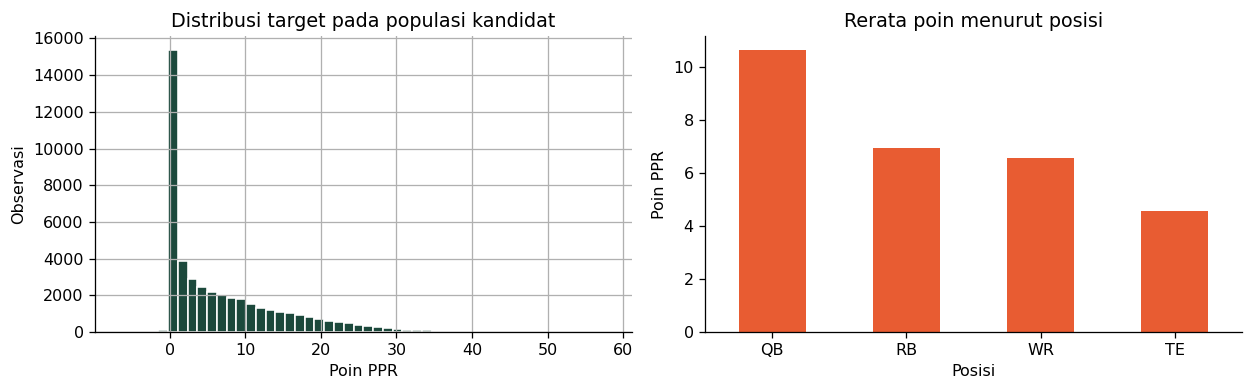

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
data.target.hist(bins=50, ax=axes[0], color='#1c493c', edgecolor='white')
axes[0].set(title='Distribusi target pada populasi kandidat', xlabel='Poin PPR', ylabel='Observasi')
data.groupby('position').target.mean().reindex(['QB','RB','WR','TE']).plot.bar(ax=axes[1], color='#e85c32', rot=0)
axes[1].set(title='Rerata poin menurut posisi', xlabel='Posisi', ylabel='Poin PPR')
plt.tight_layout()
plt.show()

## 4. Pemilihan model berdasarkan waktu

Model dibandingkan dengan baseline rata-rata lima hasil terakhir. Versi 5 menambahkan snap ofensif dan indikator cedera pekan sebelumnya. Kandidat meliputi regresi, model per posisi, model dua tahap, serta campuran dengan V3. Fitur baru mencakup kestabilan poin, peluang bermain, produksi tanpa touchdown, dan riwayat lintas musim. Rerata serta median dibandingkan karena touchdown dan beberapa skor ekstrem dapat memperbesar galat. Kandidat dan bobot campuran dicatat dalam v5_plan.json sebelum pemodelan.

| Tahap | Data latih | Data validasi atau uji |
|---|---|---|
| Fold validasi 1 | 2019–2022 | 2023 |
| Fold validasi 2 | 2019–2023 | 2024 |
| Evaluasi akhir | 2019–2024 | 2025 dan 2026 yang tersedia |

Pemilihan V5 meminimalkan rerata RMSE validasi, dengan MAE tidak boleh lebih tinggi dari V3 dan RMSE harus turun sedikitnya 0,25%. Setelah dipilih, model evaluasi dilatih ulang pada 2019–2024 dan dievaluasi pada data uji. Data 2025–2026 sudah pernah diperiksa pada versi 1. Pada versi 3, data ini tetap menjadi pengujian ulang retrospektif. Seleksi tetap hanya memakai validasi 2023–2024, dengan MAE validasi tidak meningkat dan RMSE turun minimal 0,25% terhadap V3. Hasil pengujian ulang belum merupakan konfirmasi independen pada data baru. Model forecast kemudian dilatih ulang pada seluruh pertandingan lengkap yang tersedia, termasuk pertandingan yang sebelumnya menjadi data uji. Model evaluasi dan model forecast disimpan terpisah.

Fitur statistik pertandingan target tidak digunakan. Standardisasi, imputasi, dan encoding dipelajari hanya dari bagian latih pada setiap fit.

In [6]:
RETRAIN = False
if RETRAIN:
    # Memakai sumber cache agar hasil dapat direproduksi.
    # Jika sumber diperbarui, hasil dan tanggal snapshot juga dapat berubah.
    from upgrade_v5 import run as run_upgrade
    run_upgrade()
    from refresh_forecasts import refresh
    refresh(download=False)
    from pregame_forecasts import update as update_role
    update_role()
    from availability import update as update_availability
    update_availability(download=False)
    from prospective import replay, score_all, export_panels
    replay()
    score_all()
    export_panels()
metrics = json.loads((ROOT / 'reports/metrics.json').read_text(encoding='utf-8'))
cv = pd.DataFrame([{'model': c['model'], 'MAE_validasi': c['cv_mae'],
                   'MAE_2023': c['folds'][0]['mae'], 'MAE_2024': c['folds'][1]['mae']}
                  for c in metrics['cv_candidates']]).sort_values('MAE_validasi')
display(cv.round(4))
print('Model terpilih:', metrics['selected_model'])

Model terpilih: v3+75pct_v5_role_hurdle


,model,MAE_validasi,MAE_2023,MAE_2024
5,v5_role_fair,4.0920,4.0288,4.1553
8,v3+75pct_v5_role_fair,4.1279,4.0667,4.1891
19,role_mean+75pct_v5_role_fair,4.1339,4.0716,4.1962
7,v3+50pct_v5_role_fair,4.1782,4.1199,4.2365
18,role_mean+50pct_v5_role_fair,4.1885,4.1274,4.2495
6,v3+25pct_v5_role_fair,4.2427,4.1886,4.2968
17,role_mean+25pct_v5_role_fair,4.2560,4.1970,4.3150
11,v3+50pct_v5_role_hurdle,4.3045,4.2469,4.3621
10,v3+25pct_v5_role_hurdle,4.3071,4.2538,4.3604
15,v3+50pct_v5_role_position,4.3087,4.2528,4.3647


## 5. Hasil pengujian

MAE menunjukkan besar selisih absolut rata-rata dalam satuan poin PPR. Misalnya, prediksi 15 poin dan hasil 11 poin menghasilkan galat absolut 4 poin. RMSE memberi bobot lebih besar pada kesalahan yang besar. R² menunjukkan perbaikan terhadap prediksi rata-rata target pada sampel evaluasi.

Ketiganya bukan persentase ketepatan kelas. Karena itu, proyek ini tidak menyebut MAE atau R² sebagai akurasi klasifikasi.

In [7]:
test = pd.read_csv(ROOT / 'reports/predictions_test.csv', float_precision='round_trip')
summary = pd.DataFrame({'Train': metrics['train'], 'Test': metrics['test'], 'Baseline test': metrics['baseline']}).T
display(summary.round(4))
print(f"Penurunan MAE terhadap baseline: {metrics['mae_improvement_pct']:.2f}%")
by_position = pd.DataFrame([{'posisi': p, 'n': r['model']['n'], 'MAE_model': r['model']['mae'],
                             'MAE_baseline': r['baseline']['mae'], 'RMSE_model': r['model']['rmse']}
                            for p,r in metrics['by_position'].items()]).set_index('posisi')
display(by_position.round(4))
display(pd.DataFrame([{'musim': y, 'n': r['model']['n'], 'MAE_model': r['model']['mae'],
                       'MAE_baseline': r['baseline']['mae']}
                      for y,r in metrics['by_season'].items()]).round(4))

Penurunan MAE terhadap baseline: 9.72%


,n,mae,rmse,r2
Train,36290.0,4.1819,5.8716,0.4734
Test,8288.0,4.3184,6.0970,0.4121
Baseline test,8288.0,4.7835,6.7749,0.2741


,n,MAE_model,MAE_baseline,RMSE_model
posisi,,,,
QB,1047,5.5238,6.4211,7.4884
RB,2027,4.4455,4.7937,6.2788
TE,1852,3.4854,3.8960,4.9796
WR,3362,4.3253,4.7562,6.0621


,musim,n,MAE_model,MAE_baseline
0,2025,6158,4.2838,4.6849
1,2026,2130,4.4185,5.0684


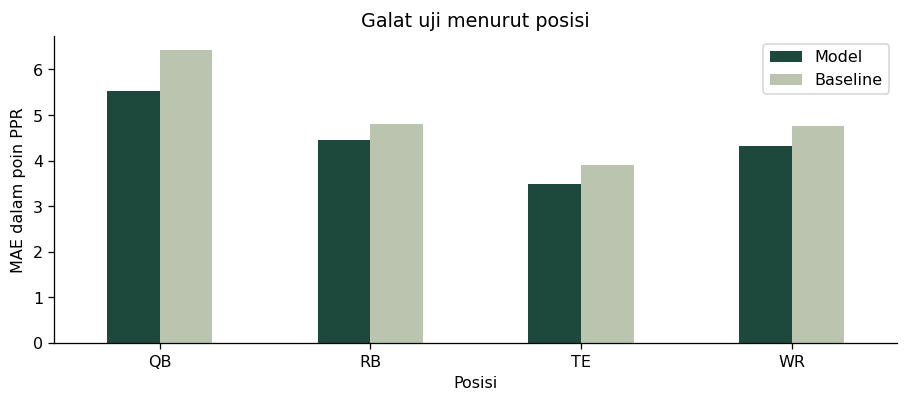

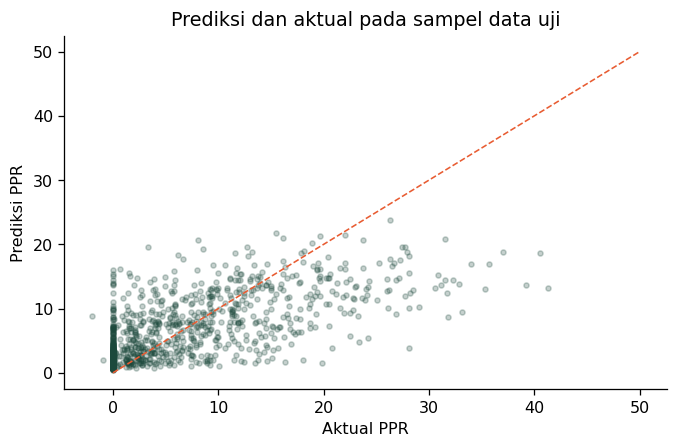

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
by_position[['MAE_model','MAE_baseline']].plot.bar(ax=ax, color=['#1c493c','#bbc4af'], rot=0)
ax.set(title='Galat uji menurut posisi', ylabel='MAE dalam poin PPR', xlabel='Posisi')
ax.legend(['Model','Baseline'])
plt.tight_layout()
plt.savefig(ROOT / 'reports/mae_by_position.png', dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
sample = test.sample(min(1000,len(test)), random_state=42)
ax.scatter(sample.target, sample.prediction, s=10, alpha=.25, color='#1c493c')
ax.plot([0,50],[0,50], '--', color='#e85c32', linewidth=1)
ax.set(title='Prediksi dan aktual pada sampel data uji', xlabel='Aktual PPR', ylabel='Prediksi PPR')
plt.tight_layout()
plt.savefig(ROOT / 'reports/predicted_vs_actual.png', dpi=160)
plt.show()

Model mencapai **MAE 4.32 poin PPR**, dibandingkan **4.78 poin** pada baseline, pada **8,288 observasi uji**. Penurunan galatnya sekitar **9.72%**. R² uji sebesar **0.412** menunjukkan bahwa prediksi per pemain masih memiliki ketidakpastian yang berarti.

Galat train sebesar **4.18** dan galat test sebesar **4.32** tidak menunjukkan selisih besar pada protokol ini. Hal tersebut tidak membuktikan model bebas overfitting atau selalu berlaku pada musim mendatang. Seluruh posisi dalam data uji memiliki MAE lebih rendah daripada baseline, tetapi QB memiliki galat absolut paling besar.

## 6. Rentang galat dan pemeriksaan contoh

Rentang memakai persentil ke-80 galat absolut validasi per posisi, lalu diletakkan secara simetris di sekitar prediksi. Batas bawah dipotong pada nol untuk tampilan. Poin fantasy aktual dapat bernilai negatif. Ini merupakan rentang galat empiris, bukan interval yang dijamin valid untuk setiap pemain.

Cakupan diuji kembali pada data uji. Perhitungan rentang berbagi fold pengembangan dengan proses pemilihan model, sehingga keterbatasan tersebut perlu dipertimbangkan.

In [9]:
print(f"Cakupan rentang pada data uji: {metrics['interval']['coverage_test']*100:.2f}%")
display(pd.Series(metrics['interval']['half_width_by_position'], name='setengah_lebar_rentang'))
audit = test[['name','position','season','week','target','prediction','baseline']].copy()
audit['galat_absolut'] = abs(audit.target-audit.prediction)
display(audit.sample(12, random_state=42).round(2))
display(audit.nlargest(10,'galat_absolut').round(2))

Cakupan rentang pada data uji: 79.16%


QB    9.312877
RB    6.824342
TE    5.177015
WR    7.005784
Name: setengah_lebar_rentang, dtype: float64

,name,position,season,week,target,prediction,baseline,galat_absolut
7951,Roschon Johnson,RB,2026,6,14.5,4.41,6.15,10.09
353,Jeremy McNichols,RB,2025,3,13.8,1.95,1.25,11.85
1746,Bam Knight,RB,2025,6,12.4,1.71,9.40,10.69
4279,David Montgomery,RB,2025,14,14.3,7.69,9.06,6.61
2955,Troy Franklin,WR,2025,10,15.0,12.96,11.94,2.04
1315,Brock Wright,TE,2025,5,8.9,1.86,3.93,7.04
233,Devaughn Vele,WR,2025,2,7.3,3.77,2.30,3.53
7055,AJ Barner,TE,2026,4,2.2,9.02,7.70,6.82
7495,Malik Benson,WR,2026,5,1.6,1.38,0.20,0.22
3543,Tony Pollard,RB,2025,12,8.1,9.51,7.70,1.41


,name,position,season,week,target,prediction,baseline,galat_absolut
3650,Jahmyr Gibbs,RB,2025,12,55.40,19.68,21.58,35.72
7076,Tetairoa McMillan,WR,2026,4,45.20,10.81,9.77,34.39
5369,Derrick Henry,RB,2025,17,45.60,12.27,16.84,33.33
6164,Davante Adams,WR,2026,2,39.50,6.80,5.60,32.70
4669,Kyle Pitts,TE,2025,15,45.60,13.01,8.78,32.59
502,Tre Tucker,WR,2025,3,40.90,8.48,9.15,32.42
2544,Drake London,WR,2025,9,38.80,6.74,15.10,32.06
2843,Jonathan Taylor,RB,2025,10,49.60,19.23,26.92,30.37
5127,Puka Nacua,WR,2025,16,46.50,16.28,21.56,30.22
7453,Jayden Daniels,QB,2026,5,32.26,2.22,8.10,30.04


## 7. Prediksi laga berikutnya musim 2026–2027

Prediksi ini menggunakan model forecast yang dilatih ulang dengan semua hasil yang tersedia setelah eksperimen evaluasi selesai. Hanya pertandingan yang belum dimulai pada waktu snapshot yang boleh menjadi target. Setiap pemain diarahkan ke pertandingan berikutnya dari tim terakhir yang diketahui. Tim yang bye dapat memiliki target pekan 9, sementara tim lain menargetkan pekan 8. Optimasi lineup dibatasi pada satu pekan.

Pemain yang terakhir terlihat lebih dari satu pekan lalu ditandai untuk pemeriksaan. Kondisi tersebut dapat disebabkan bye week, cedera, perubahan peran, atau keterlambatan statistik. Tanda ini bukan diagnosis cedera.

,name,position,team,opponent,week,prediction,low,high,baseline,risk
277,Jahmyr Gibbs,RB,DET,MIN,8,21.49,14.67,28.32,27.48,Roster ACT. Status aktif saat laga belum dipas...
52,Josh Allen,QB,BUF,BAL,8,20.99,11.68,30.30,25.12,Roster ACT. Status aktif saat laga belum dipas...
301,Drake Maye,QB,NE,MIA,8,20.54,11.23,29.86,24.12,Roster ACT. Status aktif saat laga belum dipas...
192,Joe Burrow,QB,CIN,TEN,8,20.41,11.09,29.72,23.19,Roster ACT. Status aktif saat laga belum dipas...
66,Trevor Lawrence,QB,JAX,IND,8,20.05,10.74,29.36,17.62,Roster ACT. Status aktif saat laga belum dipas...
208,Amon-Ra St. Brown,WR,DET,MIN,8,20.02,13.02,27.03,19.94,Roster ACT. Status aktif saat laga belum dipas...
249,Jaxon Smith-Njigba,WR,SEA,CHI,8,19.11,12.10,26.11,25.49,Roster ACT. Status aktif saat laga belum dipas...
235,Brock Purdy,QB,SF,LV,9,19.00,9.68,28.31,19.29,Roster ACT. Status aktif saat laga belum dipas...
245,Kenneth Walker III,RB,KC,DEN,8,18.42,11.59,25.24,22.72,Roster ACT. Status aktif saat laga belum dipas...
276,Puka Nacua,WR,LA,LAC,8,17.91,10.91,24.92,20.24,Roster ACT. Status aktif saat laga belum dipas...


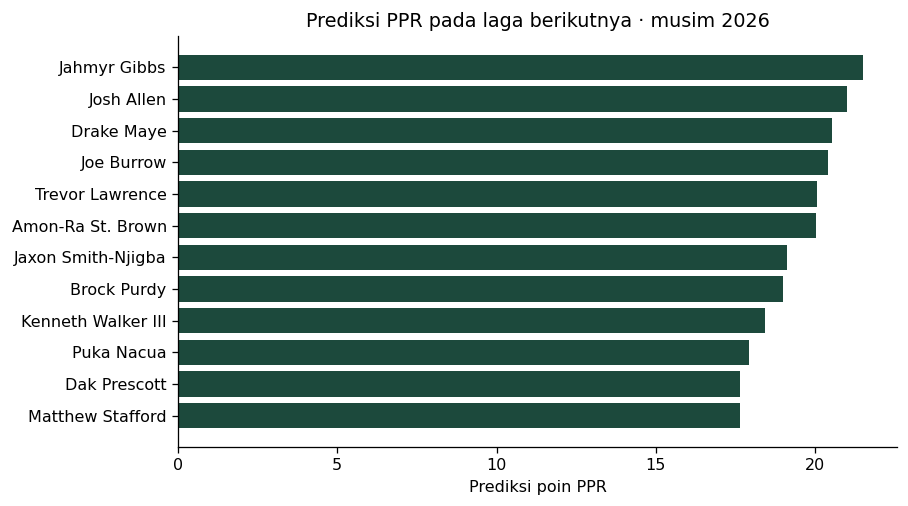

In [10]:
forecast = pd.read_csv(ROOT / 'reports/forecasts_next_game.csv')
display(forecast[['name','position','team','opponent','week','prediction','low','high','baseline','risk']]
        .sort_values('prediction', ascending=False).head(20).round(2))
top = forecast.nlargest(12,'prediction').sort_values('prediction')
fig, ax = plt.subplots(figsize=(8,4.5))
ax.barh(top.name, top.prediction, color='#1c493c')
ax.set(title='Prediksi PPR pada laga berikutnya · musim 2026', xlabel='Prediksi poin PPR')
plt.tight_layout()
plt.savefig(ROOT / 'reports/top_forecasts.png', dpi=160)
plt.show()

## 8. Start or Sit dan penyusunan lineup

Start or Sit membandingkan prediksi dua pemain. Selisih kecil dengan rentang galat yang tumpang tindih perlu dibaca sebagai keputusan yang belum pasti. Statistik pada kartu adalah konteks masukan, bukan penjelasan kausal atau nilai SHAP.

Lineup lab hanya menggunakan pemain yang dimasukkan pengguna ke roster. Algoritma mencoba setiap RB, WR, dan TE sebagai FLEX. Untuk setiap kandidat FLEX, algoritma mengambil pemain dengan prediksi tertinggi pada slot wajib yang tersisa. Kombinasi dengan jumlah prediksi tertinggi dipilih. Pemain tidak boleh muncul dua kali.

Implementasi JavaScript pada `dist/app.js` diperiksa dengan enumerasi semua kombinasi pada 20 roster acak kecil. Roster contoh pada dashboard hanya untuk demonstrasi.

In [11]:
# Contoh perbandingan dua WR dari daftar prediksi.
pair = forecast[forecast.position=='WR'].nlargest(2,'prediction')
display(pair[['name','prediction','low','high','baseline']].round(2))
gap = pair.prediction.iloc[0]-pair.prediction.iloc[1]
print(f"Selisih prediksi: {gap:.2f} poin PPR. Periksa kelayakan bermain sebelum memilih.")

Selisih prediksi: 0.92 poin PPR. Periksa kelayakan bermain sebelum memilih.


,name,prediction,low,high,baseline
208,Amon-Ra St. Brown,20.02,13.02,27.03,19.94
249,Jaxon Smith-Njigba,19.11,12.10,26.11,25.49


## 9. Verifikasi, keterbatasan, dan langkah berikutnya

Pemeriksaan integritas memastikan ID pemain-musim-pekan unik, semua prediksi bernilai hingga, dan MAE yang dilaporkan sesuai CSV. Pemeriksaan kebocoran data mengubah hasil pekan 3 dan memastikan fitur untuk pekan 3 tetap sama, sedangkan fitur untuk pekan sesudahnya berubah.

Roster dan cedera memakai snapshot nflverse. Status aktif saat laga tetap perlu diperiksa. Tim yang berbeda dari tim model disisihkan dari lineup. Snapshot benchmark berbeda dari data forecast terbaru. Pemain sebelum penampilan pertama belum diprediksi. Touchdown dan perubahan peran juga sulit diprediksi.

Bagian tambahan mendokumentasikan pemeriksaan roster, prediksi terkunci, dan evaluasi lineup simulasi terhadap baseline. Konfirmasi prospektif harus menunggu hasil pertandingan baru. Metrik pengurangan MAE tidak boleh disebut sebagai peningkatan total poin lineup, karena keduanya berbeda.

In [12]:
verification = json.loads((ROOT / 'reports/verification.json').read_text(encoding='utf-8'))
display(pd.Series(verification['checks'], name='lulus'))
assert all(verification['checks'].values())
print('Dashboard lokal: jalankan python -m http.server 8766 --directory dist dari folder proyek.')
print('Buka http://localhost:8766 di browser.')
date_checks = json.loads((ROOT / 'reports/forecast_date_verification.json').read_text(encoding='utf-8'))
display(pd.Series(date_checks))
assert all(v for v in date_checks.values() if isinstance(v, bool))

Dashboard lokal: jalankan python -m http.server 8766 --directory dist dari folder proyek.
Buka http://localhost:8766 di browser.


same_week_outcomes_do_not_change_same_week_features      True
v2_enhanced_features_have_no_same_week_target_leakage    True
later_forecasts_respond_to_new_history                   True
unique_player_season_week                                True
test_seasons_frozen                                      True
missing_source_game_excluded_not_zero                    True
reported_mae_matches_predictions                         True
finite_next_game_forecasts                               True
Name: lulus, dtype: bool

week7_not_forecast_after_completion              True
first_week8_kickoff_wib_correct                  True
started_game_removed_even_if_scores_missing      True
US_DST_conversion_correct                        True
January2027_belongs_to_season2026                True
postseason_not_silently_forecast                 True
each_player_targets_next_game_of_team            True
all_forecasts_after_asof                         True
week7_or_later_complete                          True
source_gaps_disclosed                            True
forecast_n                                        384
weeks                                          [8, 9]
dtype: object

## 10. Ketersediaan dan evaluasi prospektif

Status roster dan cedera dicocokkan menggunakan ID pemain, tim, dan pekan target. ACT berarti berada pada roster aktif, bukan jaminan bermain. Pemain nonaktif, tim berbeda, Out/Doubtful, atau bukti roster melebihi 48 jam tidak dipilih oleh lineup otomatis. Laporan yang belum tersedia bukan bukti bahwa pemain sehat.

Snapshot pada `reports/frozen` disimpan sebelum kickoff menggunakan waktu penguncian sesungguhnya. CSV prediksi, pilihan lineup, hash model, dan sumber disimpan tanpa menimpa snapshot lama. Hasil dinilai terpisah setelah skor akhir dan statistik kedua tim tersedia. Belum ada angka prospektif jika laga belum selesai.

Evaluasi lineup historis menggunakan 30 roster simulasi per pekan dengan seed tetap. Kedua kebijakan memilih dari roster yang sama. Pemilihan hanya memakai prediksi atau rerata lima hasil sebelumnya. Nilai aktual dipakai setelah lineup dipilih. Roster simulasi bukan data kepemilikan liga dan tidak menerapkan filter status aktif dan cedera pada laga target. Banyak roster pada pekan sama bukan pengamatan independen.

In [13]:
availability = json.loads((ROOT / 'reports/availability.json').read_text(encoding='utf-8'))
lineup_report = json.loads((ROOT / 'reports/lineup_replay.json').read_text(encoding='utf-8'))
prospective = json.loads((ROOT / 'reports/prospective_evaluation.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'Kandidat': availability['total'], 'Lolos pemeriksaan roster': availability['eligible'], 'Laporan cedera terbaru': availability['injury_latest_week']}]))
display(pd.DataFrame([{k: lineup_report[k] for k in ['n_rosters','n_weeks','model_mean_points','baseline_mean_points','mean_difference','win_rate']}]))
display(pd.DataFrame([{k: row[k] for k in ['snapshot_id','n_frozen','n_scored','n_pending','status']} for row in prospective]))

,Kandidat,Lolos pemeriksaan roster,Laporan cedera terbaru
0,384,358,7


,n_rosters,n_weeks,model_mean_points,baseline_mean_points,mean_difference,win_rate
0,690,23,87.984638,83.783884,4.200754,0.557971


,snapshot_id,n_frozen,n_scored,n_pending,status
0,20261027T142654305226Z,384,0,384,Menunggu laga masa depan
1,20261027T153303340647Z,384,0,384,Menunggu laga masa depan
2,20261027T153827774633Z,384,0,384,Menunggu laga masa depan


## 11. Riwayat percobaan sebelum data snap

Percobaan lanjutan membandingkan model per posisi, prediksi dua tahap, konteks peluang tim dari pekan sebelumnya, pembobotan musim terbaru, dan campuran model. Seluruh pemilihan memakai validasi 2023–2024. Model pengganti harus memiliki MAE validasi yang tidak meningkat dan RMSE validasi turun minimal 0,25%. Model yang hanya memperbaiki satu ukuran tidak otomatis menggantikan versi sekarang.

Toleransi ditetapkan sebesar 3 dan 5 poin PPR sebelum perhitungan. Persentase di bawah berarti bagian prediksi dengan galat absolut yang tidak melebihi batas tersebut. Angka ini bukan akurasi klasifikasi. Data pengujian ulang mencakup kandidat dengan hasil nol, sehingga hasil untuk observasi bukan nol juga ditampilkan. Evaluasi tetap bersifat retrospektif.

In [14]:
optimization = json.loads((ROOT / 'reports/optimization_summary.json').read_text(encoding='utf-8'))
print('Jumlah konfigurasi termasuk pembanding:', optimization['candidate_count'])
print('Status:', optimization['status'])
display(pd.DataFrame([{'model': 'Versi 3', **optimization['reference_cv']}, optimization['lowest_rmse_candidate']]).round(4))
tolerance = metrics['tolerance']
display(pd.DataFrame([{'Ukuran': label, 'Model (%)': tolerance['model'][key] * 100, 'Baseline (%)': tolerance['baseline'][key] * 100} for label, key in [('Galat maksimal 5 poin', 'within_5'), ('Galat maksimal 3 poin', 'within_3'), ('Galat maksimal 5 poin, aktual bukan nol', 'nonzero_within_5')]]).round(2))
print('Jumlah observasi aktual bukan nol:', tolerance['model']['nonzero_n'])

Jumlah konfigurasi termasuk pembanding: 61
Status: No candidate met both validation requirements. V3 predictions and locked snapshots retained.
Jumlah observasi aktual bukan nol: 5688


,model,cv_mae,cv_rmse
0,Versi 3,4.3190,6.1762
1,v3+50pct_v4_hurdle,4.3467,6.1625


,Ukuran,Model (%),Baseline (%)
0,Galat maksimal 5 poin,69.87,64.60
1,Galat maksimal 3 poin,51.29,47.67
2,"Galat maksimal 5 poin, aktual bukan nol",62.94,59.41


## 12. Peran sebelum laga dan kandidat fantasy

Data tambahan berasal dari snap counts dan laporan cedera nflverse. Hanya pekan sebelum target yang dipakai. Pembaruan cedera bertanggal setelah tanggal target dikeluarkan. Identitas PFR dan GSIS dicocokkan secara unik tanpa pencocokan nama yang samar. Ketiadaan sumber tidak dianggap nol. Kandidat tanpa snap pada laga yang datanya tersedia dapat memiliki nol setelah identitasnya dikenal dari pekan sebelumnya.

Kandidat fantasy ditentukan sebelum melihat target. QB memerlukan rerata tiga laga minimal 15 passing attempts atau persentase snap terakhir minimal 50%. RB, WR, dan TE memerlukan rerata kesempatan minimal lima atau persentase snap tiga laga minimal 25%. Bukti snap yang diketahui tidak boleh lebih lama dari dua pekan. Kriteria ini menunjukkan relevansi dari riwayat peran dan bukan konfirmasi aktif saat laga.

Metrik utama tetap memakai seluruh populasi agar perbandingan model adil. Subset fantasy dinilai terpisah menggunakan baris yang sama untuk model baru, V3, dan baseline. Waktu publikasi pertama seluruh arsip snap tidak tersedia, sehingga hasil historis merupakan replay. Prediksi baru dikunci dengan sumber dan cutoff yang tercatat.

In [15]:
pregame = json.loads((ROOT / 'reports/v5_comparison.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'Populasi': label, 'N': pregame[key]['n'], 'MAE V3': pregame[key]['v3']['mae'], 'MAE model': pregame[key]['model']['mae'], 'RMSE V3': pregame[key]['v3']['rmse'], 'RMSE model': pregame[key]['model']['rmse'], 'Maksimal 5 poin model (%)': pregame[key]['tolerance']['model']['within_5']*100} for label, key in [('Seluruh kandidat', 'full_cohort'), ('Subset fantasy', 'fantasy_pool')]]).round(4))
display(pd.Series(pregame['source_coverage']))
plan = json.loads((ROOT / 'reports/v5_plan.json').read_text(encoding='utf-8'))
display(pd.Series(plan['snap_history_coverage_by_season'], name='cakupan riwayat snap'))
print(pregame['replay_status'])

2025/26 already inspected. Retrospective replay only.


,Populasi,N,MAE V3,MAE model,RMSE V3,RMSE model,Maksimal 5 poin model (%)
0,Seluruh kandidat,8288,4.3349,4.3184,6.1826,6.0970,69.8721
1,Subset fantasy,6193,5.0590,5.0385,6.8406,6.7452,62.3607


snap_rows                       183217
snap_rows_mapped                123578
ambiguous_player_ids_removed         1
dtype: int64

2019    0.901091
2020    0.944435
2021    0.940493
2022    0.788483
2023    0.970962
2024    0.949492
2025    0.997239
2026    0.997183
Name: cakupan riwayat snap, dtype: float64